In [820]:
from tokenizers import Tokenizer
import torch
import matplotlib.pyplot as plt

# Tokenizadores

In [821]:
tokenizador = Tokenizer.from_file("./data/tokenizer.json")
texto = "O gato dorme"

tokens = [5, 8, 2, 9, 4, 7]
context_size = 3
stride = 1

In [822]:
resultado = tokenizador.encode(texto)
# ['O', 'Ġga', 'to', 'Ġdor', 'me'] => Ġ representa espaço
print(resultado.tokens)
print(resultado.ids)

['O', 'Ġga', 'to', 'Ġdor', 'me']
[47, 4326, 287, 4956, 547]


In [823]:
texto_reconstruido = tokenizador.decode(resultado.ids)
print(texto_reconstruido)
print(texto_reconstruido == texto)

O gato dorme
True


# Ids

In [824]:
entrada = resultado.ids[:-1]
alvo = resultado.ids[1:]

print(entrada, alvo)

[47, 4326, 287, 4956] [4326, 287, 4956, 547]


# Stride

In [825]:
for i in range(0, len(tokens) - context_size, stride):
    print("i = ", i)
    x = tokens[i: i + context_size]
    y = tokens[i + 1: i + context_size + 1]
    print(x, y)

i =  0
[5, 8, 2] [8, 2, 9]
i =  1
[8, 2, 9] [2, 9, 4]
i =  2
[2, 9, 4] [9, 4, 7]


# Tensores

In [826]:
x = []
y = []

for i in range(0, len(tokens) - context_size, stride):
    print("i = ", i)
    x.append(tokens[i: i + context_size])
    y.append(tokens[i + 1: i + context_size + 1])
    print(x, y)
    
tensor_x = torch.tensor(x, dtype=torch.long)
tensor_y = torch.tensor(y, dtype=torch.long)
print(tensor_x, tensor_y)
print(tensor_x.shape)
print(tensor_y.shape)

i =  0
[[5, 8, 2]] [[8, 2, 9]]
i =  1
[[5, 8, 2], [8, 2, 9]] [[8, 2, 9], [2, 9, 4]]
i =  2
[[5, 8, 2], [8, 2, 9], [2, 9, 4]] [[8, 2, 9], [2, 9, 4], [9, 4, 7]]
tensor([[5, 8, 2],
        [8, 2, 9],
        [2, 9, 4]]) tensor([[8, 2, 9],
        [2, 9, 4],
        [9, 4, 7]])
torch.Size([3, 3])
torch.Size([3, 3])


# Batch

In [827]:
batch_size = 2


def batching(tensor_list, size=batch_size):
    batch = []
    for i in range(0, len(tensor_list), size):
        batch.append(tensor_list[i : i + size])

    return batch


batched_x = batching(tensor_x)
batched_y = batching(tensor_y)

print(batched_x, batched_y)
print(len(batched_x), len(batched_y))

[tensor([[5, 8, 2],
        [8, 2, 9]]), tensor([[2, 9, 4]])] [tensor([[8, 2, 9],
        [2, 9, 4]]), tensor([[9, 4, 7]])]
2 2


# Embeddings

In [828]:
num_embeddings = 10
num_dimensions = 4

embeddings = torch.nn.Embedding(num_embeddings, num_dimensions)

In [829]:
token_vectors = embeddings(batched_x[0])

print(token_vectors)
print("Tabela:", embeddings.weight.shape)
print("Entrada:", batched_x[0].shape)
print("Resultado:", token_vectors.shape)
print(embeddings.weight[8])

tensor([[[ 0.9569,  1.1356, -0.8085,  1.3484],
         [ 0.3681, -0.0668,  0.2251, -0.9304],
         [-1.5717,  1.2004, -0.3512,  0.3243]],

        [[ 0.3681, -0.0668,  0.2251, -0.9304],
         [-1.5717,  1.2004, -0.3512,  0.3243],
         [-2.3650, -0.1692,  0.2417,  1.2756]]], grad_fn=<EmbeddingBackward0>)
Tabela: torch.Size([10, 4])
Entrada: torch.Size([2, 3])
Resultado: torch.Size([2, 3, 4])
tensor([ 0.3681, -0.0668,  0.2251, -0.9304], grad_fn=<SelectBackward0>)


# Posição

In [830]:
num_linhas = 3
num_componentes = 4

posicao = torch.nn.Embedding(num_linhas, num_componentes)
value = torch.arange(num_linhas)

In [831]:
position_vectors = posicao(value)
print(position_vectors, position_vectors.shape)

tensor([[ 0.6738, -2.1183, -1.5421,  2.0949],
        [-0.4071, -0.1117,  0.4103, -0.7292],
        [ 0.4533, -1.0187,  1.5871, -0.7124]], grad_fn=<EmbeddingBackward0>) torch.Size([3, 4])


In [832]:
input_vectors = position_vectors + token_vectors
print(input_vectors, input_vectors.shape)
print("Tokens:", token_vectors)
print("Posições:", position_vectors)

tensor([[[ 1.6307, -0.9828, -2.3506,  3.4433],
         [-0.0391, -0.1785,  0.6354, -1.6596],
         [-1.1184,  0.1817,  1.2358, -0.3881]],

        [[ 1.0419, -2.1851, -1.3170,  1.1645],
         [-1.9789,  1.0887,  0.0591, -0.4048],
         [-1.9117, -1.1879,  1.8287,  0.5631]]], grad_fn=<AddBackward0>) torch.Size([2, 3, 4])
Tokens: tensor([[[ 0.9569,  1.1356, -0.8085,  1.3484],
         [ 0.3681, -0.0668,  0.2251, -0.9304],
         [-1.5717,  1.2004, -0.3512,  0.3243]],

        [[ 0.3681, -0.0668,  0.2251, -0.9304],
         [-1.5717,  1.2004, -0.3512,  0.3243],
         [-2.3650, -0.1692,  0.2417,  1.2756]]], grad_fn=<EmbeddingBackward0>)
Posições: tensor([[ 0.6738, -2.1183, -1.5421,  2.0949],
        [-0.4071, -0.1117,  0.4103, -0.7292],
        [ 0.4533, -1.0187,  1.5871, -0.7124]], grad_fn=<EmbeddingBackward0>)


# Atenção

In [833]:
camadas_lineares = [
    torch.nn.Linear(4, 4, bias=False),
    torch.nn.Linear(4, 4, bias=False),
    torch.nn.Linear(4, 4, bias=False),
]

chamadas = []

for linear in camadas_lineares:
    chamadas.append(linear(input_vectors))

queries, keys, values = chamadas
chamadas = []

print(queries, keys, values)

tensor([[[ 1.5086, -1.2576,  1.7859,  0.5561],
         [-0.1061,  0.6965, -0.6344, -0.5384],
         [-0.7689, -0.1432, -0.8795,  0.3377]],

        [[ 1.4566, -0.6989,  0.2162, -0.2221],
         [-1.1360, -0.2122, -0.6358, -0.0550],
         [-0.7242, -1.1480, -1.7666,  0.8757]]], grad_fn=<UnsafeViewBackward0>) tensor([[[-0.4998, -0.1237,  0.8518,  1.1124],
         [ 0.0483, -0.0052, -0.6480, -0.1525],
         [ 0.2205,  0.2844, -0.1156, -0.1652]],

        [[-0.1934,  0.2091, -0.1266,  1.1909],
         [ 0.9451,  0.1847,  0.8954, -1.2465],
         [ 0.3534,  0.8650, -0.1689,  0.5971]]], grad_fn=<UnsafeViewBackward0>) tensor([[[-0.3730,  0.4761, -1.1808,  0.1423],
         [ 0.4483, -0.4914,  0.1774, -0.4023],
         [-0.3341,  0.5694,  0.4617,  0.3161]],

        [[ 0.1339,  0.1847, -1.0799, -0.7542],
         [-0.3173,  0.0835,  0.7253, -0.1054],
         [-0.8888,  1.7425,  0.2335,  0.3645]]], grad_fn=<UnsafeViewBackward0>)


In [834]:
resultado_produto_escalar = []
for i in range(3):
    resultado_produto_escalar.append(sum(queries[0, 1] * keys[0, i]))
    
tensor_pe = torch.stack(resultado_produto_escalar)
half_tensor_pe = tensor_pe/2
print(resultado_produto_escalar)
print(tensor_pe)
print(half_tensor_pe)


[tensor(-1.1725, grad_fn=<AddBackward0>), tensor(0.4845, grad_fn=<AddBackward0>), tensor(0.3370, grad_fn=<AddBackward0>)]
tensor([-1.1725,  0.4845,  0.3370], grad_fn=<StackBackward0>)
tensor([-0.5863,  0.2422,  0.1685], grad_fn=<DivBackward0>)


In [835]:
mascara = half_tensor_pe.clone()
mascara[2] = float("-inf")
print(mascara)

tensor([-0.5863,  0.2422,    -inf], grad_fn=<CopySlices>)


In [836]:
attention_weights = torch.softmax(mascara, dim=0)
print(attention_weights)
print(attention_weights.sum())

tensor([0.3040, 0.6960, 0.0000], grad_fn=<SoftmaxBackward0>)
tensor(1.0000, grad_fn=<SumBackward0>)


In [837]:
weighted_vectors = []
for i in range(3):
    weighted_vectors.append(attention_weights[i]*values[0, i])
    
weighted_vectors = torch.stack(weighted_vectors)
print(weighted_vectors)
print(weighted_vectors.sum(dim=0))

tensor([[-0.1134,  0.1447, -0.3589,  0.0432],
        [ 0.3120, -0.3421,  0.1235, -0.2800],
        [-0.0000,  0.0000,  0.0000,  0.0000]], grad_fn=<StackBackward0>)
tensor([ 0.1987, -0.1973, -0.2355, -0.2367], grad_fn=<SumBackward1>)


# Implementando atenção

In [838]:
chamadas = []
camadas_lineares = [
    torch.nn.Linear(4, 4, bias=False),
    torch.nn.Linear(4, 4, bias=False),
    torch.nn.Linear(4, 4, bias=False),
]

for linear in camadas_lineares:
    chamadas.append(linear(input_vectors))

queries, keys, values = chamadas

In [839]:
# deprecated
def calcular_pontuacoes_test(queries, keys):
    save3 = []

    for i in range(len(queries)):
        save2 = []
        for j in range(len(queries[i])):
            save = []
            for k in range(len(queries[i])):
                save.append(sum(queries[i, j] * keys[i, k]) / 2)

            save2.append(torch.stack(save))

        save3.append(torch.stack(save2))

    return torch.stack(save3)

In [840]:
# New
def calcular_pontuacoes(queries, keys):
    dimensao = keys.shape[-1] ** 0.5
    transposed_keys = keys.transpose(-2, -1)
    return (queries @ transposed_keys) / dimensao

In [841]:
# deprecated
def sliding_mascara(tensors):
    mascaras = []
    for index in range(len(tensors)):
        print(tensors[index])
        mascara = tensors[index].clone()
        mascara[index + 1 : len(mascara)] = float("-inf")
        mascaras.append(mascara)

    return torch.stack(mascaras)

In [842]:
# new
def aplicar_mascara_causal(pontuacoes):
    pontuacoes_mascara = pontuacoes.clone()
    for exemplos_index in range(len(pontuacoes_mascara)):
        tokens_tamanho = len(pontuacoes_mascara[exemplos_index])
        for tokens_index in range(tokens_tamanho):
            pontuacoes_mascara[exemplos_index][tokens_index][tokens_index + 1 : tokens_tamanho] = float("-inf")

    return pontuacoes_mascara


In [843]:
def calcular_pesos(pontuacoes_mascaradas):
    return torch.softmax(pontuacoes_mascaradas, dim=-1)

In [844]:
def combinar_values(pesos, values):
    return pesos @ values

In [845]:
def atencao_causal(queries, keys, values):
    tensor_pe = calcular_pontuacoes(queries, keys)
    pontuacoes_mascaradas = aplicar_mascara_causal(tensor_pe)
    pesos = calcular_pesos(pontuacoes_mascaradas)
    contextos = combinar_values(pesos, values)
    return pesos, contextos

In [846]:
pesos, contextos = atencao_causal(queries, keys, values)

# Testes

In [847]:
test2 = pesos @ values
print(test2.shape)
print(torch.allclose(contextos, test2))

torch.Size([2, 3, 4])
True


# Validação se altera o futuro

In [848]:
queries_clone = queries.clone()
keys_clone = keys.clone()
values_clone = values.clone()

queries_clone[0][2] += 10
keys_clone[0][2] += 10
values_clone[0][2] += 10

In [849]:
pesos_clone, contexto_clone = atencao_causal(queries_clone, keys_clone, values_clone)
print(torch.allclose(contexto_clone[0][0], contextos[0][0]))
print(torch.allclose(contexto_clone[0][1], contextos[0][1]))


True
True


# Melhorando atencao

In [850]:
class AtencaoCausal(torch.nn.Module):
    def __init__(self, dimensao_entrada, dimensao_saida=0):
        super().__init__()
        self.dimensao_entrada = dimensao_entrada
        self.dimensao_saida = (
            dimensao_entrada if dimensao_saida <= 0 else dimensao_saida
        )
        self.camada_linear_query = torch.nn.Linear(
            dimensao_entrada, self.dimensao_saida, bias=False
        )
        self.camada_linear_key = torch.nn.Linear(
            dimensao_entrada, self.dimensao_saida, bias=False
        )
        self.camada_linear_value = torch.nn.Linear(
            dimensao_entrada, self.dimensao_saida, bias=False
        )

    def forward(self, x):
        queries = self.camada_linear_query(x)
        keys = self.camada_linear_key(x)
        values = self.camada_linear_value(x)
        return atencao_causal(queries, keys, values)

In [851]:
atencao_cabeça_1 = AtencaoCausal(4, 2)
atencao_cabeça_2 = AtencaoCausal(4, 2)


In [852]:
peso_atencao_1, contexto_atencao_1 = atencao_cabeça_1(input_vectors)
print(peso_atencao_1, contexto_atencao_1)
peso_atencao_2, contexto_atencao_2 = atencao_cabeça_2(input_vectors)
print(peso_atencao_2, contexto_atencao_2)

tensor([[[1.0000, 0.0000, 0.0000],
         [0.1120, 0.8880, 0.0000],
         [0.2700, 0.3598, 0.3703]],

        [[1.0000, 0.0000, 0.0000],
         [0.6200, 0.3800, 0.0000],
         [0.1977, 0.3763, 0.4260]]], grad_fn=<SoftmaxBackward0>) tensor([[[ 1.6021,  1.0528],
         [ 0.0431, -0.3965],
         [ 0.1167, -0.0042]],

        [[ 1.4984,  0.1848],
         [ 0.4223,  0.2505],
         [-0.4214,  0.0904]]], grad_fn=<UnsafeViewBackward0>)
tensor([[[1.0000, 0.0000, 0.0000],
         [0.3607, 0.6393, 0.0000],
         [0.4711, 0.2324, 0.2965]],

        [[1.0000, 0.0000, 0.0000],
         [0.3962, 0.6038, 0.0000],
         [0.4201, 0.2254, 0.3545]]], grad_fn=<SoftmaxBackward0>) tensor([[[-1.0550,  1.3785],
         [ 0.0636,  0.2951],
         [-0.3270,  0.4941]],

        [[-0.2787,  1.0670],
         [-0.6111, -0.2999],
         [-0.4375,  0.2795]]], grad_fn=<UnsafeViewBackward0>)


In [853]:
contexto_cabecas = torch.cat(
    (contexto_atencao_1, contexto_atencao_2), dim=2
)

projecao_saida = torch.nn.Linear(4, 4, bias=False)
contexto_projetado = projecao_saida(contexto_cabecas)

print(contexto_projetado)
print(contexto_projetado.shape)

tensor([[[-0.3902,  0.8074, -0.9598, -0.1772],
         [ 0.0793,  0.2826, -0.0026, -0.1208],
         [ 0.1318,  0.2664, -0.2391, -0.0448]],

        [[-0.4830,  0.9221, -0.5040, -0.3613],
         [ 0.0326, -0.0508, -0.2920,  0.1119],
         [ 0.3671, -0.0425, -0.1873,  0.1160]]], grad_fn=<UnsafeViewBackward0>)
torch.Size([2, 3, 4])


# Atenção de multiplas cabeças

In [854]:
class AtencaoMultiplasCabecas(torch.nn.Module):
    def __init__(self, dimensao_entrada, dimensao_saida=0, qtd_cabecas=1):
        super().__init__()
        self.dimensao_entrada = dimensao_entrada

        self.dimensao_saida = (
            dimensao_entrada if dimensao_saida <= 0 else dimensao_saida
        )

        if qtd_cabecas <= 0:
            raise ValueError(
                "A quantidade de cabeças precisa ser maior que zero."
            )

        if self.dimensao_saida % qtd_cabecas != 0:
            raise ValueError(
                "A dimensão de saída precisa ser divisível pela quantidade de cabeças."
            )

        self.qtd_cabecas = qtd_cabecas

        self.cabecas = torch.nn.ModuleList(
            [
                AtencaoCausal(
                    dimensao_entrada,
                    self.dimensao_saida // self.qtd_cabecas,
                )
                for _ in range(self.qtd_cabecas)
            ]
        )

        self.saida_linear = torch.nn.Linear(
            self.dimensao_saida,
            self.dimensao_saida,
            bias=False,
        )

    def forward(self, x):
        cabecas_atencao_contextos = []

        for index in range(len(self.cabecas)):
            cabecas_atencao_contextos.append(
                self.cabecas[index](x)[1]
            )

        cabecas_atencao = torch.cat(
            cabecas_atencao_contextos, dim=2
        )

        return self.saida_linear(cabecas_atencao)

In [855]:
multi_cabecas = AtencaoMultiplasCabecas(4, 4, 2)
saida_multi_cabecas = multi_cabecas(input_vectors)

print(saida_multi_cabecas)
print(saida_multi_cabecas.shape)

clone_input_vector = input_vectors.clone()
clone_input_vector[0, 2] += 10

saida_multi_cabecas_clone = multi_cabecas(clone_input_vector)

print(
    torch.allclose(
        saida_multi_cabecas_clone[0, 0],
        saida_multi_cabecas[0, 0],
    )
)

print(
    torch.allclose(
        saida_multi_cabecas_clone[0, 1],
        saida_multi_cabecas[0, 1],
    )
)

tensor([[[ 0.0319,  0.5751,  0.0449, -0.5797],
         [-0.1926, -0.0504, -0.1155,  0.0801],
         [-0.0450, -0.1980,  0.0066,  0.2197]],

        [[-0.3267, -0.1935, -0.2296,  0.2374],
         [ 0.1253,  0.0302,  0.0195, -0.0641],
         [ 0.3594, -0.2268,  0.2507,  0.1933]]], grad_fn=<UnsafeViewBackward0>)
torch.Size([2, 3, 4])
True
True


# Normalização

In [856]:
saida_residual = input_vectors + saida_multi_cabecas

print(saida_residual)
print(saida_residual.shape)

tensor([[[ 1.6626, -0.4077, -2.3056,  2.8636],
         [-0.2317, -0.2289,  0.5199, -1.5794],
         [-1.1635, -0.0163,  1.2424, -0.1684]],

        [[ 0.7153, -2.3786, -1.5466,  1.4020],
         [-1.8536,  1.1189,  0.0786, -0.4689],
         [-1.5523, -1.4147,  2.0794,  0.7565]]], grad_fn=<AddBackward0>)
torch.Size([2, 3, 4])


In [857]:
vetor_teste = torch.tensor([1.0, 3.0, 5.0, 7.0])

media = vetor_teste.mean()
var = vetor_teste.var(unbiased=False)
normalizacao = (vetor_teste - media) / (var + 1e-5) ** 0.5

print("Vetor: ", vetor_teste)
print("Média: ", media)
print("Variância: ", var)
print("Vetor normalizado: ", normalizacao)

Vetor:  tensor([1., 3., 5., 7.])
Média:  tensor(4.)
Variância:  tensor(5.)
Vetor normalizado:  tensor([-1.3416, -0.4472,  0.4472,  1.3416])


In [858]:
def normalizacao(vetor):
    media = vetor.mean(dim=2, keepdim=True)
    var = vetor.var(unbiased=False, dim=2, keepdim=True)
    normalizacao = (vetor - media) / (var + 1e-5) ** 0.5
    return normalizacao

In [859]:
print(normalizacao(saida_residual))

tensor([[[ 0.6119, -0.4356, -1.3959,  1.2196],
         [ 0.1959,  0.1996,  1.1885, -1.5840],
         [-1.3301,  0.0119,  1.4843, -0.1661]],

        [[ 0.7492, -1.2366, -0.7026,  1.1900],
         [-1.4666,  1.3060,  0.3356, -0.1750],
         [-0.9964, -0.9062,  1.3850,  0.5175]]], grad_fn=<DivBackward0>)


# LayerNorm

In [860]:
class LayerNorm(torch.nn.Module):
    def __init__(self, qtd_componentes):
        super().__init__()
        self.qtd_componentes = qtd_componentes
        self.epsilon = 1e-5
        self.vetor_escala = torch.nn.Parameter(torch.ones(qtd_componentes))
        self.vetor_deslocamento = torch.nn.Parameter(torch.zeros(qtd_componentes))

    def forward(self, x):
        normalizado = self.normalizacao(x)
        resultado = self.vetor_escala * normalizado + self.vetor_deslocamento
        return resultado

    def normalizacao(self, vetor, eixo=-1):
        media = vetor.mean(dim=eixo, keepdim=True)
        var = vetor.var(unbiased=False, dim=eixo, keepdim=True)
        normalizacao = (vetor - media) / (var + self.epsilon) ** 0.5
        return normalizacao

In [861]:
layer = LayerNorm(4)
layer_saida_residual = layer(saida_residual)
print(layer_saida_residual)

tensor([[[ 0.6119, -0.4356, -1.3959,  1.2196],
         [ 0.1959,  0.1996,  1.1885, -1.5840],
         [-1.3301,  0.0119,  1.4843, -0.1661]],

        [[ 0.7492, -1.2366, -0.7026,  1.1900],
         [-1.4666,  1.3060,  0.3356, -0.1750],
         [-0.9964, -0.9062,  1.3850,  0.5175]]], grad_fn=<AddBackward0>)


# MLP

In [862]:
class MLP(torch.nn.Module):
    def __init__(self, dimensao):
        super().__init__()
        self.dimensao = dimensao
        self.expansao = torch.nn.Linear(dimensao, 4 * dimensao)
        self.ativacao = torch.nn.GELU()
        self.projecao_saida = torch.nn.Linear(4 * dimensao, dimensao)

    def forward(self, x):
        expansao_vetor = self.expansao(x)
        ativacao_vetor = self.ativacao(expansao_vetor)
        projecao_saida_vetor = self.projecao_saida(ativacao_vetor)
        return projecao_saida_vetor

In [863]:
mlp = MLP(4)
mlp_saida_residual = mlp(layer_saida_residual)

In [864]:
conexao_residual_mlp = saida_residual + mlp_saida_residual

# print(layer_saida_residual)
# print(mlp_saida_residual)
print(conexao_residual_mlp)

tensor([[[ 1.1376, -1.1868, -2.5969,  2.5948],
         [-0.4068, -0.1139,  0.5644, -1.4993],
         [-0.9382, -0.1759,  1.1018, -0.1280]],

        [[ 0.5061, -2.9501, -1.7519,  1.2045],
         [-2.0660,  0.6743, -0.2086, -0.5553],
         [-1.1300, -1.6440,  1.9342,  0.7964]]], grad_fn=<AddBackward0>)


In [865]:
class BlocoTransformer(torch.nn.Module):
    def __init__(self, dimensao, qtd_cabecas):
        super().__init__()
        self.norm_atencao = LayerNorm(dimensao)
        self.atencao = AtencaoMultiplasCabecas(dimensao,dimensao, qtd_cabecas)
        self.norm_mlp = LayerNorm(dimensao)
        self.mlp = MLP(dimensao)
        
    def forward(self, x):
        entrada = self.norm_atencao(x)
        entrada_normalizada = self.atencao(entrada)
        residual_atencao = x + entrada_normalizada
        residual_normalizada = self.norm_mlp(residual_atencao)
        saida_mlp = self.mlp(residual_normalizada)
        saida_bloco = residual_atencao + saida_mlp
        return saida_bloco

In [866]:
bloco_transformer = BlocoTransformer(4, 2)
saida_bloco = bloco_transformer(input_vectors)

In [867]:
camada_linear = torch.nn.Linear(4, 10, bias=False)
logits = camada_linear(saida_bloco)

In [868]:
print(torch.argmax(logits, dim=-1))
print(batched_y[0])

tensor([[8, 9, 6],
        [2, 6, 9]])
tensor([[8, 2, 9],
        [2, 9, 4]])


In [869]:
softmax_logits = torch.softmax(logits[0][0], dim=0)
log = -torch.log(softmax_logits[8])
print(log)

tensor(0.8752, grad_fn=<NegBackward0>)


In [870]:
save_error = []
choosen_batch = batched_y[0]
for i in range(len(choosen_batch)):
    save_error_example = []
    for j in range(len(choosen_batch[i])):
        softmax_logits = torch.softmax(logits[i][j], dim=0)
        save_error_example.append(-torch.log(softmax_logits[choosen_batch[i, j]]))

    save_error.append(torch.stack(save_error_example))

resultado = torch.stack(save_error)
print(resultado)
print(resultado.mean())

tensor([[0.8752, 2.6497, 1.4798],
        [1.3344, 1.5330, 4.2043]], grad_fn=<StackBackward0>)
tensor(2.0127, grad_fn=<MeanBackward0>)


In [871]:
logits_entropia = logits.reshape(-1, logits.shape[-1])
batch_entropia = batched_y[0].reshape(-1)
print(logits_entropia)
print(batch_entropia)

tensor([[ 0.9284, -0.2914,  0.8714, -1.0906, -1.0738,  0.7217, -2.2762, -0.6044,
          1.8762, -2.4893],
        [-0.2371,  0.1462, -0.1368,  0.3613,  0.3471, -0.2449,  0.6423,  0.1330,
         -0.6125,  0.8345],
        [ 0.0779,  0.3297, -0.0501, -0.4417, -0.2013, -0.1601,  1.1874,  0.2390,
         -0.2387,  1.1830],
        [ 0.7576,  0.3366,  1.2466, -0.3421, -0.8490,  0.5212, -1.8294, -0.8169,
          0.9064, -1.2078],
        [-0.1144, -0.3495, -0.4858, -0.4253,  0.8498, -0.7375,  1.6327,  0.7661,
         -0.4563,  1.3193],
        [ 0.6999,  1.0522,  0.8005, -1.1274, -1.3312,  0.2494,  0.9652, -0.2237,
          0.2559,  1.3863]], grad_fn=<ViewBackward0>)
tensor([8, 2, 9, 2, 9, 4])


In [872]:
erro = torch.nn.functional.cross_entropy(logits_entropia, batch_entropia)
erro.backward()

In [873]:
print(camada_linear.weight.grad)
print(camada_linear.weight.grad.shape)

tensor([[-0.0432, -0.1156, -0.0232,  0.0858],
        [-0.0946, -0.0758,  0.0479,  0.0256],
        [-0.0461,  0.2325,  0.0276,  0.1879],
        [-0.0336, -0.0180,  0.0117, -0.0063],
        [ 0.3307,  0.2359, -0.3002, -0.0903],
        [-0.0225, -0.0909, -0.0244,  0.0662],
        [-0.2418,  0.0430,  0.1155, -0.0222],
        [-0.0859,  0.0025,  0.0285,  0.0020],
        [-0.1590,  0.0576,  0.2121, -0.2654],
        [ 0.3959, -0.2712, -0.0955,  0.0168]])
torch.Size([10, 4])


In [874]:
sgd = torch.optim.SGD(camada_linear.parameters(), lr=0.1)
pesos_antes = camada_linear.weight.detach().clone()

sgd.step()

print(torch.allclose(pesos_antes, camada_linear.weight))

False


In [875]:
logits_2 = camada_linear(saida_bloco)
logits_entropia_2 = logits_2.reshape(-1, logits_2.shape[-1])
erro2 = torch.nn.functional.cross_entropy(logits_entropia_2, batch_entropia)

In [876]:
print(torch.allclose(erro, erro2))
print(erro, erro2)

False
tensor(2.0127, grad_fn=<NllLossBackward0>) tensor(1.9267, grad_fn=<NllLossBackward0>)


In [877]:
class GptPequeno(torch.nn.Module):
    def __init__(self, tamanho_vocabulario, context_size, dimensao, qtd_cabecas):
        super().__init__()
        self.embedding_tokens = torch.nn.Embedding(tamanho_vocabulario, dimensao)
        self.embedding_posicoes = torch.nn.Embedding(context_size, dimensao)
        self.transformer = BlocoTransformer(dimensao, qtd_cabecas)
        self.layer_norm = LayerNorm(dimensao)
        self.projecao_logits = torch.nn.Linear(dimensao, tamanho_vocabulario, bias=False)
    
    def forward(self, x):
        embeddings_tokens = self.embedding_tokens(x)
        indices_posicoes = torch.arange(0, x.shape[1], device=x.device)
        embeddings_posicoes = self.embedding_posicoes(indices_posicoes)
        entrada_transformer = embeddings_tokens + embeddings_posicoes
        saida_transformer = self.transformer(entrada_transformer)
        saida_normalizada = self.layer_norm(saida_transformer)
        logits = self.projecao_logits(saida_normalizada)
        return logits

In [878]:
gpt = GptPequeno(10,3,4,2)
gpt_resultado = gpt(batched_x[0])
print(gpt_resultado)
print(gpt_resultado.shape)


tensor([[[ 1.0384,  0.6152,  0.9245,  0.9095, -0.0151,  0.8129,  0.5615,
          -0.1949, -0.5751, -0.7733],
         [ 0.5090, -0.0089, -0.0238,  0.0105,  0.0881,  0.3094,  1.0173,
           1.0109,  0.0505, -0.5724],
         [-0.0720,  0.8316,  0.7642, -0.1483, -0.7854, -0.0561,  0.7872,
          -0.8208, -1.1050, -0.6873]],

        [[ 1.0184,  0.0962,  0.3276,  0.6903,  0.3423,  0.7492,  0.6299,
           0.7297,  0.0601, -0.5748],
         [-0.7550, -0.0255, -0.3930, -1.0093, -0.4897, -0.6496,  0.6728,
           0.2731, -0.1832, -0.0962],
         [ 0.6624,  0.9046,  1.0449,  0.4536, -0.5006,  0.5041,  1.0126,
          -0.4797, -1.0497, -1.0025]]], grad_fn=<UnsafeViewBackward0>)
torch.Size([2, 3, 10])


In [879]:
gpt_sgd = torch.optim.SGD(gpt.parameters(), lr=0.1)
gpt_sgd.zero_grad()

In [880]:
gpt_resultado_reshape = gpt_resultado.reshape(-1, gpt_resultado.shape[-1])
gpt_erro = torch.nn.functional.cross_entropy(gpt_resultado_reshape, batch_entropia)
gpt_erro_save = gpt_erro.detach().clone()

In [881]:
gpt_erro.backward()
gpt_sgd.step()

In [882]:
print(gpt_erro, gpt_erro_save)

tensor(2.8488, grad_fn=<NllLossBackward0>) tensor(2.8488)


In [883]:
gpt_resultado_2 = gpt(batched_x[0])
print(gpt_resultado)
print(gpt_resultado_2)

tensor([[[ 1.0384,  0.6152,  0.9245,  0.9095, -0.0151,  0.8129,  0.5615,
          -0.1949, -0.5751, -0.7733],
         [ 0.5090, -0.0089, -0.0238,  0.0105,  0.0881,  0.3094,  1.0173,
           1.0109,  0.0505, -0.5724],
         [-0.0720,  0.8316,  0.7642, -0.1483, -0.7854, -0.0561,  0.7872,
          -0.8208, -1.1050, -0.6873]],

        [[ 1.0184,  0.0962,  0.3276,  0.6903,  0.3423,  0.7492,  0.6299,
           0.7297,  0.0601, -0.5748],
         [-0.7550, -0.0255, -0.3930, -1.0093, -0.4897, -0.6496,  0.6728,
           0.2731, -0.1832, -0.0962],
         [ 0.6624,  0.9046,  1.0449,  0.4536, -0.5006,  0.5041,  1.0126,
          -0.4797, -1.0497, -1.0025]]], grad_fn=<UnsafeViewBackward0>)
tensor([[[ 0.9846,  0.5587,  0.9083,  0.8776,  0.0626,  0.7629,  0.4653,
          -0.2134, -0.4662, -0.7456],
         [ 0.4792, -0.0136,  0.0855, -0.0024,  0.0759,  0.2878,  0.9760,
           0.9638,  0.0464, -0.5700],
         [-0.1272,  0.7609,  0.6402, -0.1641, -0.7095, -0.0922,  0.6579,
    

In [884]:
gpt_resultado_reshape_2 = gpt_resultado_2.reshape(-1, gpt_resultado_2.shape[-1])
gpt_erro_2 = torch.nn.functional.cross_entropy(gpt_resultado_reshape_2, batch_entropia)

In [885]:
print(gpt_erro_2, gpt_erro_save)

tensor(2.7056, grad_fn=<NllLossBackward0>) tensor(2.8488)


In [886]:
gpt = GptPequeno(10,3,4,2)
gpt_sgd = torch.optim.SGD(gpt.parameters(), lr=0.1)

In [887]:
for i in range(100):
    gpt_sgd.zero_grad()
    gpt_resultado = gpt(batched_x[0])
    gpt_resultado_reshape = gpt_resultado.reshape(-1, gpt_resultado.shape[-1])
    gpt_erro = torch.nn.functional.cross_entropy(gpt_resultado_reshape, batch_entropia)
    gpt_erro.backward()
    gpt_sgd.step()
    
    if(i % 9 == 0):
        print(gpt_erro.item())

2.4781904220581055
1.575715184211731


0.9424896240234375
0.5225822925567627
0.3601836860179901
0.23896552622318268
0.1757345199584961
0.13369734585285187
0.3329179584980011
0.0885264053940773
0.06804418563842773
0.054590869694948196


In [888]:
@torch.no_grad()
def gerar_tokens(modelo, sequencia_inicial, quantidade_novos_tokens, tamanho_contexto):
    sequencia = sequencia_inicial.detach().clone()
    print(sequencia)
    for i in range(quantidade_novos_tokens):
        contexto = sequencia[:, -tamanho_contexto: ]
        gpt_resultado = modelo(contexto)
        logits_ultima_posicao = gpt_resultado[:, -1, :]
        previsao = torch.argmax(logits_ultima_posicao, dim=-1, keepdim=True)
        sequencia = torch.cat((sequencia, previsao), dim=1)
        print(sequencia)
        
    return sequencia

In [889]:
gerar_tokens(gpt, batched_x[0][0:1], 3, 3)

tensor([[5, 8, 2]])
tensor([[5, 8, 2, 9]])
tensor([[5, 8, 2, 9, 4]])
tensor([[5, 8, 2, 9, 4, 9]])


tensor([[5, 8, 2, 9, 4, 9]])

In [890]:
def janela_contexto(ids, tamanho_contexto, passo=1):
    janela = [[], []]

    for i in range(0, len(ids) - tamanho_contexto, passo):
        janela[0].append(ids[i : i + tamanho_contexto])
        janela[1].append(ids[i + 1 : i + tamanho_contexto + 1])

    tensor_entradas_treino = torch.tensor(janela[0], dtype=torch.long)
    tensor_alvo_treino = torch.tensor(janela[1], dtype=torch.long)

    return (tensor_entradas_treino, tensor_alvo_treino)


def lotes_agrupamento(listagens, tamanho=1):
    lotes = []
    for i in range(0, len(listagens), tamanho):
        lotes.append(listagens[i : i + tamanho])

    return lotes

In [891]:
def ler_e_tokenizar(caminho_arquivo="./data/train.txt"):
    with open(file=caminho_arquivo, encoding="utf-8") as arquivo_treino:
        texto_treino = arquivo_treino.read(2000)
        return tokenizador.encode(texto_treino)

In [892]:
tokens_treino = ler_e_tokenizar()
ids_treino = tokens_treino.ids
    
entradas_treino, alvo_treino = janela_contexto(ids_treino, 32, 32)
loteamento_entradas_treino = lotes_agrupamento(entradas_treino, 4)
loteamento_alvo_treino = lotes_agrupamento(alvo_treino, 4)

In [893]:
tamanho_vocabulario = tokenizador.get_vocab_size()
tamanho_contexto = 32
dimensao = 32
qtd_cabecas = 4
gpt_corpus = GptPequeno(tamanho_vocabulario, tamanho_contexto, dimensao, qtd_cabecas)

In [894]:
print(gpt_corpus.embedding_tokens)
print(gpt_corpus.embedding_tokens.weight.shape)
print(loteamento_entradas_treino[0].shape)
print(loteamento_entradas_treino[0].dtype)
print(tokenizador.get_vocab_size())

Embedding(16000, 32)
torch.Size([16000, 32])
torch.Size([4, 32])
torch.int64
16000


In [895]:
primeiro_lote = gpt_corpus(loteamento_entradas_treino[0])
primeiro_lote = primeiro_lote.reshape(-1, primeiro_lote.shape[-1])
loteamento_reshaped = loteamento_alvo_treino[0].reshape(-1)
print(primeiro_lote.shape, loteamento_reshaped.shape)

torch.Size([128, 16000]) torch.Size([128])


In [896]:
corpus_erro = torch.nn.functional.cross_entropy(primeiro_lote, loteamento_reshaped)
gpt_corpus_sgd = torch.optim.SGD(gpt_corpus.parameters(), lr=0.1)
gpt_corpus_sgd.zero_grad()
corpus_erro.backward()
gpt_corpus_sgd.step()

In [897]:
logits_depois = gpt_corpus(loteamento_entradas_treino[0])
logits_depois = logits_depois.reshape(-1, logits_depois.shape[-1])
corpus_erro_2 = torch.nn.functional.cross_entropy(logits_depois, loteamento_reshaped)
print(corpus_erro, corpus_erro_2)

tensor(9.8564, grad_fn=<NllLossBackward0>) tensor(9.8234, grad_fn=<NllLossBackward0>)


In [ ]:
def treinar_epoca(modelo, otimizador, lotes_entrada, lotes_alvo):
    soma_erros = 0.0
    total_tokens = 0
    modelo.train()
    
    for entradas, alvos in zip(lotes_entrada, lotes_alvo):
        otimizador.zero_grad()

        logits = modelo(entradas)
        logits = logits.reshape(-1, logits.shape[-1])

        alvo = alvos.reshape(-1)

        corpus_erro = torch.nn.functional.cross_entropy(logits, alvo)

        corpus_erro.backward()
        otimizador.step()

        soma_erros += corpus_erro.item() * alvos.numel()
        total_tokens += alvos.numel()
        
    return soma_erros / total_tokens

In [899]:
tokens_validacao = ler_e_tokenizar("./data/val.txt")
ids_validacao = tokens_validacao.ids
    
entradas_validacao, alvo_validacao = janela_contexto(ids_validacao, 32, 32)
loteamento_entradas_validacao = lotes_agrupamento(entradas_validacao, 4)
loteamento_alvo_validacao = lotes_agrupamento(alvo_validacao, 4)

print(loteamento_entradas_validacao[0].shape, loteamento_alvo_validacao[0].shape)

torch.Size([4, 32]) torch.Size([4, 32])


In [900]:
@torch.no_grad()
def avaliar_epoca(modelo, lotes_entrada, lotes_alvo):
    soma_erros = 0.0
    total_tokens = 0
    modelo.eval()

    for entradas, alvos in zip(lotes_entrada, lotes_alvo):
        logits = modelo(entradas)
        logits = logits.reshape(-1, logits.shape[-1])

        alvo = alvos.reshape(-1)

        corpus_erro = torch.nn.functional.cross_entropy(logits, alvo)

        soma_erros += corpus_erro.item() * alvos.numel()
        total_tokens += alvos.numel()

    return soma_erros / total_tokens

In [ ]:
historico_treino = []
historico_validacao = []
epocas_adicionais = 1

for i in range(10):
    print("Epoca: ", i + 1)
    historico_treino.append(
        treinar_epoca(
            gpt_corpus,
            gpt_corpus_sgd,
            loteamento_entradas_treino,
            loteamento_alvo_treino,
        )
    )
    epocas_adicionais += 1
    print("Erro médio treino: ", historico_treino[i])
    historico_validacao.append(
        avaliar_epoca(
            gpt_corpus, loteamento_entradas_validacao, loteamento_alvo_validacao
        )
    )
    print("Erro médio validação: ", historico_validacao[i])

Epoca:  1
Erro médio treino:  9.861697050241323
Erro médio validação:  9.843903414408366
Epoca:  2
Erro médio treino:  9.815404231731709
Erro médio validação:  9.83612060546875
Epoca:  3
Erro médio treino:  9.76975235572228
Erro médio validação:  9.828436470031738
Epoca:  4
Erro médio treino:  9.724402060875526
Erro médio validação:  9.820681508382162
Epoca:  5
Erro médio treino:  9.67901692023644
Erro médio validação:  9.812679481506347
Epoca:  6
Erro médio treino:  9.633253684410683
Erro médio validação:  9.804247983296712
Epoca:  7
Erro médio treino:  9.586755752563477
Erro médio validação:  9.795189158121746
Epoca:  8
Erro médio treino:  9.539144956148588
Erro médio validação:  9.785281626383464
Epoca:  9
Erro médio treino:  9.490010041456957
Erro médio validação:  9.77427406311035
Epoca:  10
Erro médio treino:  9.438897646390474
Erro médio validação:  9.761878522237142


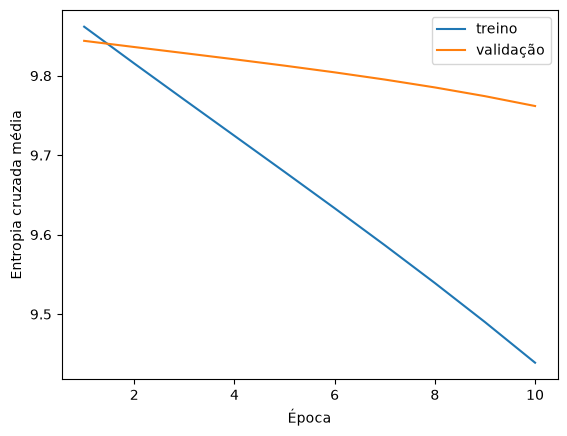

In [902]:
def grafico_historico(*historicos):
    for historico in historicos:
        plt.plot(list(range(1, len(historico[1]) + 1)), historico[1], label=historico[0])
                
    plt.xlabel("Época")
    plt.ylabel("Entropia cruzada média")
    plt.legend()
    plt.show()

grafico_historico(("treino", historico_treino), ("validação", historico_validacao))

In [903]:
configuracao = {
    "tamanho_vocabulario": 16000,
    "tamanho_contexto": 32,
    "dimensao": 32,
    "qtd_cabecas": 4,
}

In [904]:
class GptPequeno(torch.nn.Module):
    def __init__(self, tamanho_vocabulario, tamanho_contexto, dimensao, qtd_cabecas):
        super().__init__()
        self.embedding_tokens = torch.nn.Embedding(tamanho_vocabulario, dimensao)
        self.embedding_posicoes = torch.nn.Embedding(tamanho_contexto, dimensao)
        self.transformer = BlocoTransformer(dimensao, qtd_cabecas)
        self.layer_norm = LayerNorm(dimensao)
        self.projecao_logits = torch.nn.Linear(dimensao, tamanho_vocabulario, bias=False)
    
    def forward(self, x):
        embeddings_tokens = self.embedding_tokens(x)
        indices_posicoes = torch.arange(0, x.shape[1], device=x.device)
        embeddings_posicoes = self.embedding_posicoes(indices_posicoes)
        entrada_transformer = embeddings_tokens + embeddings_posicoes
        saida_transformer = self.transformer(entrada_transformer)
        saida_normalizada = self.layer_norm(saida_transformer)
        logits = self.projecao_logits(saida_normalizada)
        return logits

In [905]:
estado_modelo = gpt_corpus.state_dict()
estado_otimizador = gpt_corpus_sgd.state_dict()

In [ ]:
checkpoint = {
    "configuracao": configuracao,
    "estado_modelo": estado_modelo,
    "estado_otimizador": estado_otimizador,
    "historico": {
        "treino": historico_treino,
        "validacao": historico_validacao
    },
    "epocas_adicionais": epocas_adicionais
}

torch.save(checkpoint, "data/checkpoint_gpt_corpus.pt")

In [ ]:
checkpoint_carregado = torch.load(
    "data/checkpoint_gpt_corpus.pt", map_location="cpu", weights_only=True
)

gpt_recuperado = GptPequeno(**checkpoint_carregado["configuracao"])
gpt_recuperado.load_state_dict(checkpoint_carregado["estado_modelo"])
epocas_adicionais = checkpoint_carregado["epocas_adicionais"]

<All keys matched successfully>

In [908]:
gpt_corpus.eval()
gpt_recuperado.eval()
with torch.no_grad():
    print(
        torch.allclose(
            gpt_corpus(loteamento_entradas_validacao[0]),
            gpt_recuperado(loteamento_entradas_validacao[0]),
        )
    )

True


In [909]:
gpt_recuperado_sgd = torch.optim.SGD(gpt_recuperado.parameters(), lr=0.1)
gpt_recuperado_sgd.load_state_dict(checkpoint_carregado["estado_otimizador"])

In [ ]:
erro_antes = avaliar_epoca(
    gpt_recuperado, loteamento_entradas_validacao, loteamento_alvo_validacao
)
treino = treinar_epoca(
    gpt_recuperado,
    gpt_recuperado_sgd,
    loteamento_entradas_treino,
    loteamento_alvo_treino,
)
epocas_adicionais += 1
erro_depois = avaliar_epoca(
    gpt_recuperado, loteamento_entradas_validacao, loteamento_alvo_validacao
)

In [913]:
print("validação antes: ", erro_antes)
print("treino: ", treino)
print("validação depois: ", erro_depois)

validação antes:  9.747753270467122
treino:  9.32862377166748
validação depois:  9.73149496714274


In [ ]:
estado_modelo = gpt_recuperado.state_dict()
estado_otimizador = gpt_recuperado_sgd.state_dict()

checkpoint = {
    "configuracao": configuracao,
    "estado_modelo": estado_modelo,
    "estado_otimizador": estado_otimizador,
    "historico": {
        "treino": historico_treino,
        "validacao": historico_validacao
    },
    "epocas_adicionais": epocas_adicionais
}

torch.save(checkpoint, "data/checkpoint_gpt_corpus.pt")